# Pattern experiment (throwaway)

Turns the output of `src/segmentation.py` into a printable felt sewing pattern (PDF). Everything lives in this folder, so you can delete `experiments/` when you're done. Nothing in `src/` is changed.

**Assumptions (defaults, change them in the last cells)**
- US letter paper, longest side of the plush = 18 cm
- Flat 2-sided plush: a front and a mirrored back silhouette are sewn together and stuffed
- Every other piece from segmentation is a felt appliqué glued or stitched onto the front
- Body pieces get a 6 mm seam allowance (solid = cut, dashed = sew). Appliqués are cut exactly
- Pieces thinner than 3 mm are fattened so they can actually be cut

**Steps**
1. **Pixels to shapes:** `cv2.findContours` on each piece's mask, then smooth the pixel staircase (grow, shrink, simplify) with `shapely`
2. **Scale:** pixels to millimeters, so the longest side of the silhouette = 18 cm
3. **Pieces:** front + back body from the silhouette, one appliqué per remaining piece. Thin pieces hugging the silhouette edge are leftover outline and get dropped
4. **Felt color:** nearest named felt color, measured in Lab
5. **Layout:** shelf packing: tallest pieces first, left to right, new row/page when full
6. **Draw:** matplotlib pages sized exactly to letter paper in mm, saved as a vector PDF

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:   # walk up to the project folder
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
DATA_2D = ROOT / "data" / "test_images" / "2d"
OUT = Path.cwd()                                               # PDFs are saved next to this notebook

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 60                                # smaller previews here, the PDF stays full quality

from src.background_removal import load_rgb, remove_background
from src.segmentation import segment

## Pattern code

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.path import Path as MplPath
from shapely.geometry import Polygon, MultiPolygon
from shapely import affinity
from shapely.ops import unary_union

PAGE_W, PAGE_H = 215.9, 279.4      # US letter, in mm
MARGIN = 10                         # mm kept clear at page edges
GAP = 6                             # mm between pieces


# ---------- 1. pixels -> shapes ----------

def mask_to_polygon(mask, smooth_px=1.5):
    """Binary mask -> smoothed shapely (Multi)Polygon in pixel units, holes included."""
    contours, hierarchy = cv2.findContours(mask.astype(np.uint8), cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    if hierarchy is None:
        return None
    polys = []
    for i, c in enumerate(contours):
        if hierarchy[0][i][3] != -1 or len(c) < 3:     # skip holes here, attach them below
            continue
        holes = []
        child = hierarchy[0][i][2]
        while child != -1:
            if len(contours[child]) >= 3:
                holes.append(contours[child][:, 0, :])
            child = hierarchy[0][child][0]
        polys.append(Polygon(c[:, 0, :], holes).buffer(0))
    if not polys:
        return None
    shape = unary_union(polys)
    # round off the pixel staircase: grow then shrink, then drop extra points
    return shape.buffer(smooth_px).buffer(-smooth_px).simplify(0.8)


def mean_color(rgb, mask):
    return tuple(int(v) for v in rgb[mask].mean(0))


# ---------- 2. name felt colors ----------

FELT_COLORS = {
    "white": (245, 245, 240), "cream": (240, 228, 200), "light pink": (245, 190, 200),
    "pink": (235, 130, 160), "red": (210, 40, 45), "orange": (235, 130, 40),
    "yellow": (245, 215, 70), "light yellow": (250, 240, 160), "lime": (170, 200, 60),
    "green": (70, 160, 70), "teal": (70, 180, 175), "light blue": (170, 210, 235),
    "blue": (60, 110, 180), "navy": (25, 50, 100), "purple": (130, 90, 170),
    "tan": (210, 170, 120), "caramel": (190, 120, 40), "brown": (110, 70, 45),
    "dark brown": (60, 40, 30), "gray": (160, 160, 160), "black": (25, 25, 25),
}
_names = list(FELT_COLORS)
_lab = cv2.cvtColor(np.array([list(FELT_COLORS.values())], np.uint8), cv2.COLOR_RGB2LAB)[0].astype(float)


def felt_name(rgb):
    lab = cv2.cvtColor(np.array([[rgb]], np.uint8), cv2.COLOR_RGB2LAB)[0, 0].astype(float)
    return _names[int(np.argmin(np.linalg.norm(_lab - lab, axis=1)))]


# ---------- 3. build the piece list ----------

def build_pieces(rgba, regions, longest_mm=180, seam_mm=6, min_width_mm=3, min_area_mm2=6):
    """Front + back body (with seam allowance) and one appliqué piece per other region."""
    rgb, fg = rgba[..., :3], rgba[..., 3] > 127
    sil = mask_to_polygon(fg)
    sil = max(sil.geoms, key=lambda g: g.area) if isinstance(sil, MultiPolygon) else sil
    sil = Polygon(sil.exterior)                        # silhouette has no holes
    minx, miny, maxx, maxy = sil.bounds
    s = longest_mm / max(maxx - minx, maxy - miny)     # mm per pixel

    def to_mm(g):
        return affinity.scale(affinity.translate(g, -minx, -miny), s, s, origin=(0, 0))

    body_color = mean_color(rgb, regions == 1)
    front = to_mm(sil)
    pieces = [
        dict(name="Body front", shape=front, color=body_color, cut="cut 1", seam=seam_mm, kind="body"),
        dict(name="Body back", shape=affinity.scale(front, -1, 1, origin="center"), color=body_color,
             cut="cut 1 (mirrored)", seam=seam_mm, kind="body"),
    ]
    appliques = []
    for r in range(2, regions.max() + 1):
        m = regions == r
        g = mask_to_polygon(m)
        if g is None:
            continue
        g = to_mm(g)
        # leftover bits of the outer outline: thin pieces hugging the silhouette edge
        avg_width = 2 * g.area / max(g.length, 1e-6)
        on_edge = g.intersection(front.exterior.buffer(2)).area / max(g.area, 1e-6)
        if avg_width < 2 * min_width_mm and on_edge > 0.5:
            continue
        # felt thinner than ~3 mm can't be cut, so fatten thin pieces (mouth lines etc.)
        avg_width = 2 * g.area / max(g.length, 1e-6)
        if avg_width < min_width_mm:
            g = g.buffer((min_width_mm - avg_width) / 2)
        if g.area < min_area_mm2:
            continue
        appliques.append(dict(name="", shape=g, color=mean_color(rgb, m), cut="cut 1", seam=0, kind="applique"))
    appliques.sort(key=lambda p: -p["shape"].area)
    pieces += appliques
    for i, p in enumerate(pieces, 1):
        p["num"] = i
        p["felt"] = felt_name(p["color"])
        if not p["name"]:
            p["name"] = f"{p['felt'].capitalize()} piece"
        p["cut_shape"] = p["shape"].buffer(p["seam"], join_style="round") if p["seam"] else p["shape"]
    return pieces, front


# ---------- 4. lay pieces out on pages ----------

def pack(pieces, first_page_reserved=40):
    """Simple shelf packing: tallest first, left to right, new row when full, new page when out of room."""
    usable_w = PAGE_W - 2 * MARGIN
    order = sorted(pieces, key=lambda p: -(p["cut_shape"].bounds[3] - p["cut_shape"].bounds[1]))
    pages, page, x, y, row_h = [], [], MARGIN, MARGIN + first_page_reserved, 0
    for p in order:
        g = p["cut_shape"]
        w, h = g.bounds[2] - g.bounds[0], g.bounds[3] - g.bounds[1]
        if w > usable_w and h <= usable_w:             # turn sideways if too wide
            p["rot"] = 90
            g = affinity.rotate(g, 90, origin="centroid")
            w, h = h, w
        else:
            p["rot"] = 0
        if x + w > PAGE_W - MARGIN:                    # next row
            x, y, row_h = MARGIN, y + row_h + GAP, 0
        if y + h + 8 > PAGE_H - MARGIN:                # next page (+8 mm for the label)
            pages.append(page)
            page, x, y, row_h = [], MARGIN, MARGIN, 0
        p["dx"], p["dy"] = x - g.bounds[0], y - g.bounds[1]
        page.append(p)
        x += w + GAP
        row_h = max(row_h, h + 8)
    pages.append(page)
    return pages


def placed(p, g):
    if p["rot"]:
        g = affinity.rotate(g, 90, origin=p["cut_shape"].centroid)
    return affinity.translate(g, p["dx"], p["dy"])


# ---------- 5. draw ----------

def _patch(g, **kw):
    """shapely (Multi)Polygon -> matplotlib patch (holes included)."""
    verts, codes = [], []
    for poly in getattr(g, "geoms", [g]):
        for ring in [poly.exterior, *poly.interiors]:
            pts = np.asarray(ring.coords)
            verts += pts.tolist()
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(pts) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kw)


def _page():
    fig = plt.figure(figsize=(PAGE_W / 25.4, PAGE_H / 25.4))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, PAGE_W); ax.set_ylim(PAGE_H, 0); ax.axis("off")
    return fig, ax


def _hex(c):
    return "#%02x%02x%02x" % c


def draw_cover(title, pieces, front):
    fig, ax = _page()
    ax.text(MARGIN, 18, title, fontsize=18, weight="bold")
    ax.text(MARGIN, 25, "Assembly guide  ·  flat 2-sided plush  ·  print the pattern pages at 100% / Actual size",
            fontsize=8, color="0.35")
    # preview: front body with all appliqué pieces in place, scaled to fit
    pv = 100 / max(front.bounds[2], front.bounds[3])
    ox, oy = MARGIN, 35
    for p in pieces:
        if p["num"] == 2:
            continue
        g = affinity.translate(affinity.scale(p["shape"], pv, pv, origin=(0, 0)), ox, oy)
        ax.add_patch(_patch(g, facecolor=_hex(p["color"]), edgecolor="0.2", lw=0.6))
        if p["num"] > 2 and g.area > 4:
            c = g.representative_point()
            ax.text(c.x, c.y, str(p["num"]), fontsize=5, ha="center", va="center",
                    bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="none", alpha=0.8))
    # piece table
    tx, ty = 125, 40
    ax.text(tx, ty - 6, "Pieces", fontsize=10, weight="bold")
    for p in pieces:
        if ty > PAGE_H - MARGIN - 40:
            ax.text(tx, ty, "…more on pattern pages", fontsize=6.5); break
        ax.add_patch(Rectangle((tx, ty - 2.6), 4, 4, facecolor=_hex(p["color"]), edgecolor="0.3", lw=0.4))
        ax.text(tx + 6, ty, f"{p['num']:>2}.  {p['name']}  ·  {p['felt']} felt  ·  {p['cut']}", fontsize=6.5, va="center")
        ty += 5.5
    steps = [
        "1. Print pattern pages at 100% and check the test square measures exactly 1 inch / 2 cm.",
        "2. Cut each piece from felt in the listed color. Body pieces: cut on the solid line.",
        "3. Glue or stitch the small pieces onto the body front, larger pieces first, using the preview.",
        "4. Place front and back together (decorated side out) and blanket-stitch along the dashed line,",
        "   leaving a 4 cm gap. Stuff, then stitch the gap closed.",
    ]
    for i, s in enumerate(steps):
        ax.text(MARGIN, 160 + i * 6, s, fontsize=7.5)
    return fig


def draw_pattern_page(page, page_no, n_pages, title):
    fig, ax = _page()
    for p in page:
        cut = placed(p, p["cut_shape"])
        ax.add_patch(_patch(cut, facecolor=_hex(p["color"]) + "40", edgecolor="black", lw=0.8))
        if p["seam"]:   # sewing line, inset by the seam allowance
            ax.add_patch(_patch(placed(p, p["shape"]), facecolor="none", edgecolor="0.3", lw=0.5, ls=(0, (3, 2))))
        b = cut.bounds
        ax.text(b[0], b[3] + 4, f"#{p['num']} {p['name']}  ·  {p['felt']}  ·  {p['cut']}", fontsize=5.5)
    if page_no == 1:   # print-scale check
        ax.add_patch(Rectangle((PAGE_W - MARGIN - 25.4, PAGE_H - MARGIN - 25.4), 25.4, 25.4, fill=False, lw=0.8))
        ax.text(PAGE_W - MARGIN - 12.7, PAGE_H - MARGIN - 12.7, "1 in\ntest", fontsize=6, ha="center", va="center")
        ax.add_patch(Rectangle((PAGE_W - MARGIN - 55, PAGE_H - MARGIN - 20), 20, 20, fill=False, lw=0.8))
        ax.text(PAGE_W - MARGIN - 45, PAGE_H - MARGIN - 10, "2 cm\ntest", fontsize=6, ha="center", va="center")
    ax.text(MARGIN, PAGE_H - 5, f"{title}  ·  pattern page {page_no}/{n_pages}  ·  solid = cut line, dashed = sewing line",
            fontsize=6, color="0.4")
    return fig


def make_pattern(rgba, regions, title, pdf_path, longest_mm=180):
    pieces, front = build_pieces(rgba, regions, longest_mm=longest_mm)
    pages = pack(pieces, first_page_reserved=0)
    figs = [draw_cover(title, pieces, front)]
    figs += [draw_pattern_page(pg, i, len(pages), title) for i, pg in enumerate(pages, 1)]
    with PdfPages(pdf_path) as pdf:
        for f in figs:
            pdf.savefig(f)
    return figs, pieces

## Run it

Each run shows the cover page (assembly guide) and the pattern pages, and saves a PDF next to this notebook.

### Bunny (`easy/1e.jpg`)

6 pieces, 3 pages -> bunny_pattern.pdf


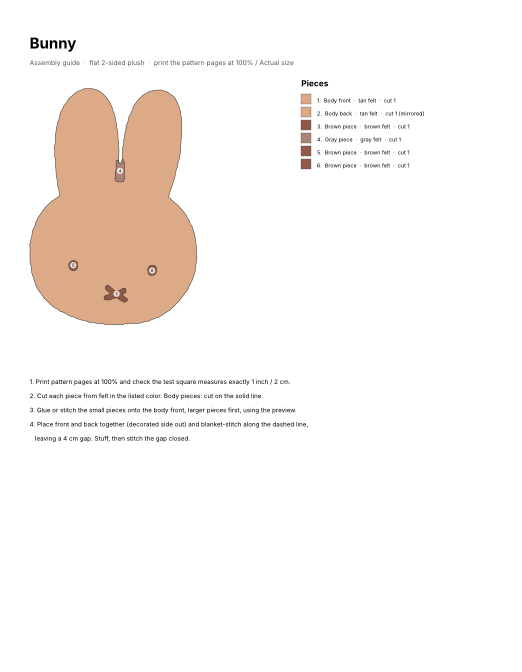

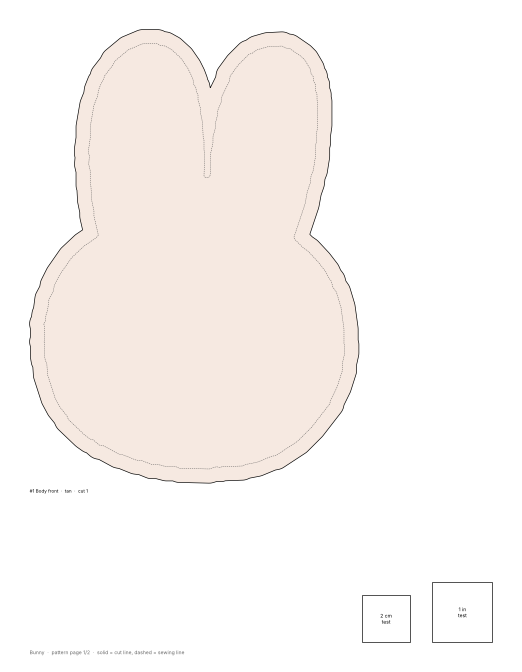

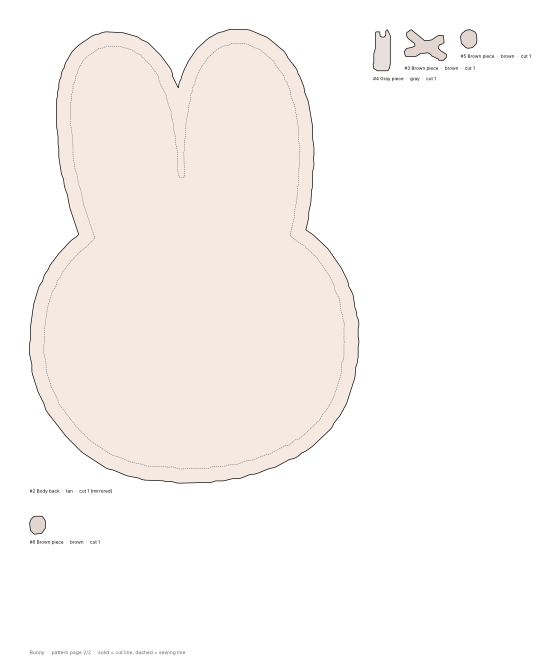

In [3]:
rgba, _ = remove_background(load_rgb(DATA_2D / "easy/1e.jpg", 1024), use_ai_fallback=False)
regions, _ = segment(rgba)
figs, pieces = make_pattern(rgba, regions, "Bunny", OUT / "bunny_pattern.pdf", longest_mm=180)
print(f"{len(pieces)} pieces, {len(figs)} pages -> bunny_pattern.pdf")

### Bear (`medium/3m.jpg`)

16 pieces, 4 pages -> bear_pattern.pdf


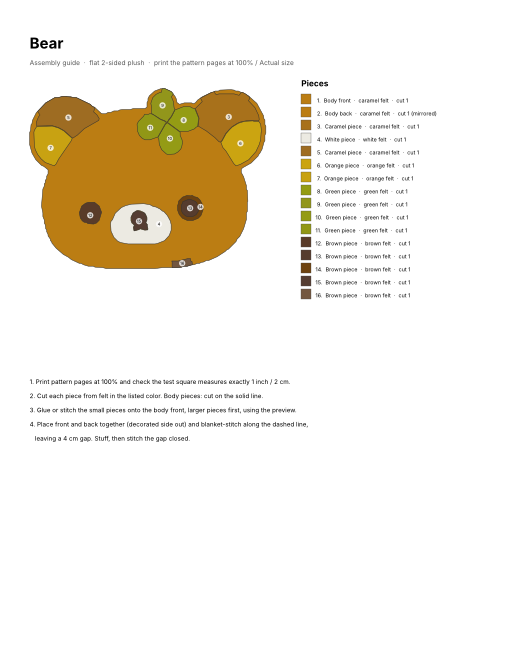

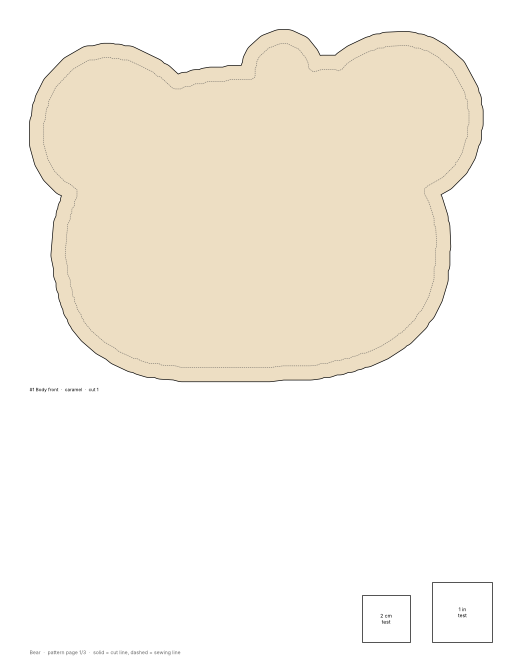

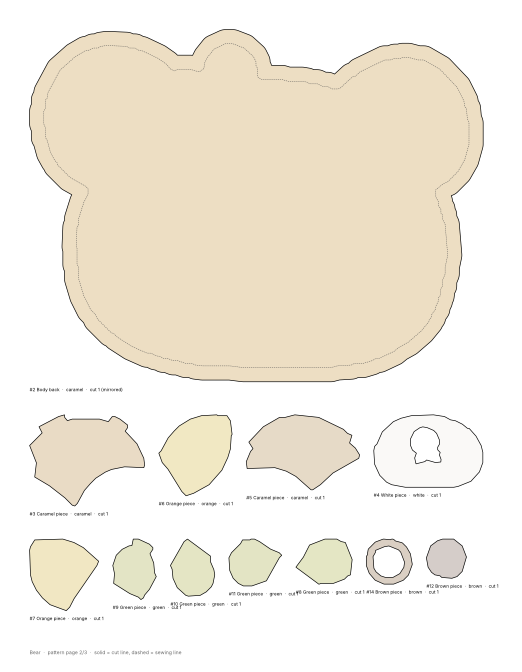

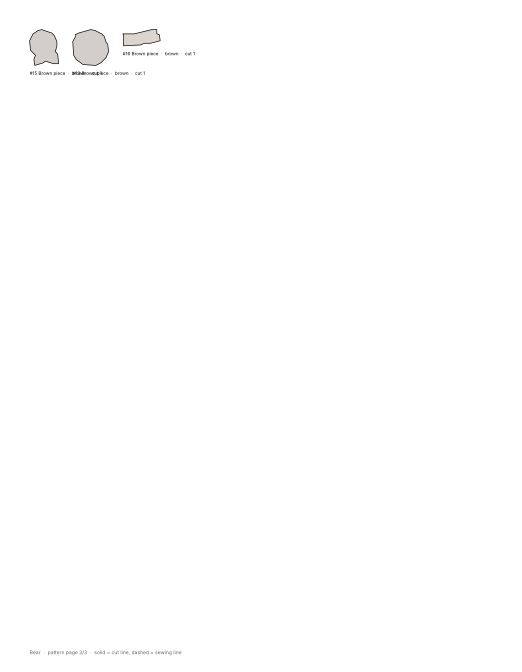

In [4]:
rgba, _ = remove_background(load_rgb(DATA_2D / "medium/3m.jpg", 1024), use_ai_fallback=False)
regions, _ = segment(rgba)
figs, pieces = make_pattern(rgba, regions, "Bear", OUT / "bear_pattern.pdf", longest_mm=180)
print(f"{len(pieces)} pieces, {len(figs)} pages -> bear_pattern.pdf")

### Tamagotchi (`medium/4m.jpg`)

22 pieces, 4 pages -> tamagotchi_pattern.pdf


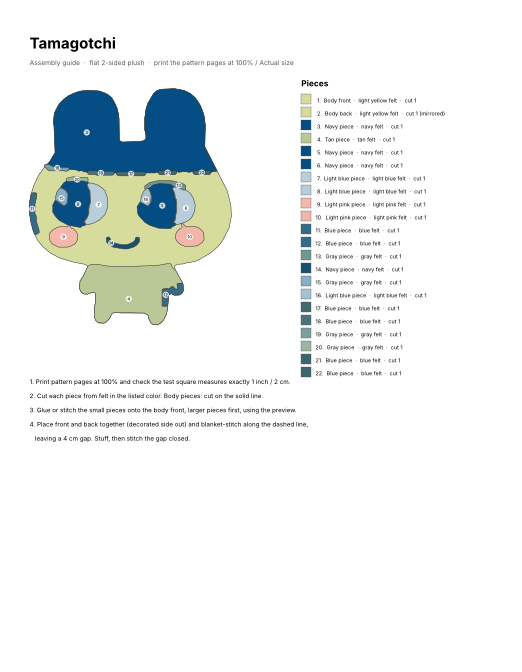

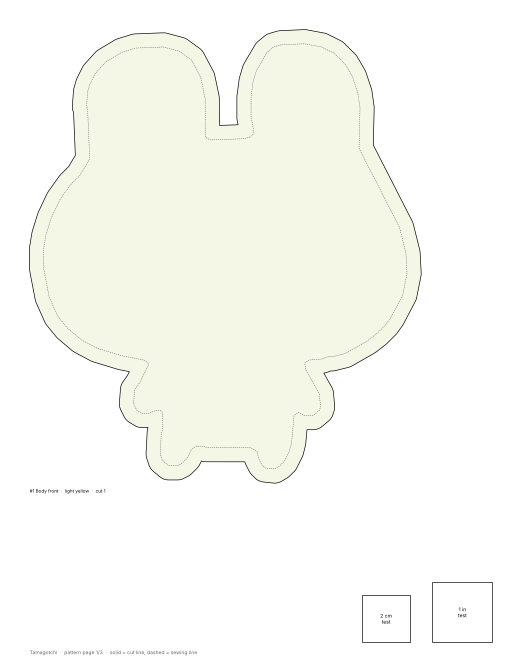

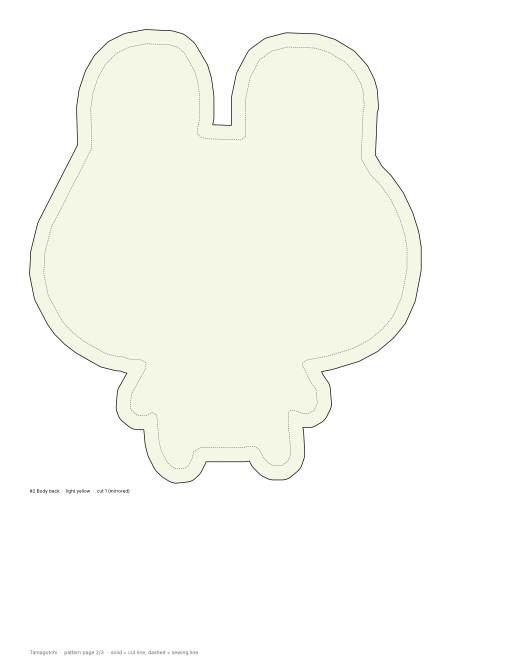

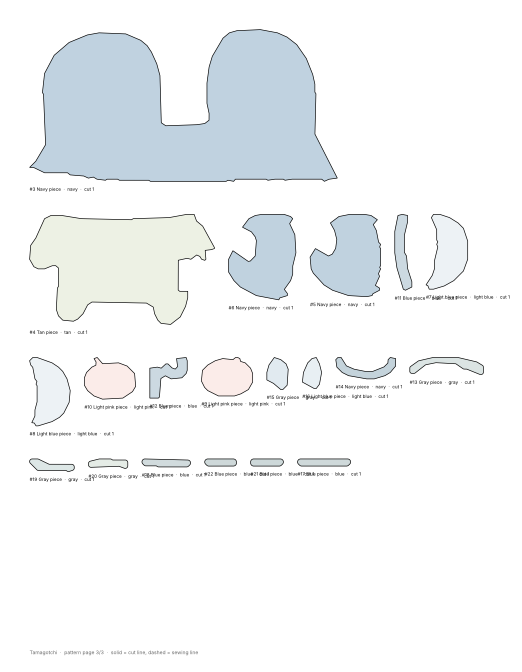

In [5]:
rgba, _ = remove_background(load_rgb(DATA_2D / "medium/4m.jpg", 1024), use_ai_fallback=False)
regions, _ = segment(rgba)
figs, pieces = make_pattern(rgba, regions, "Tamagotchi", OUT / "tamagotchi_pattern.pdf", longest_mm=180)
print(f"{len(pieces)} pieces, {len(figs)} pages -> tamagotchi_pattern.pdf")